# Small Dataset - Network Traffic Anomaly Detection

This notebook compares supervised classification and unsupervised anomaly detection methods on the small network traffic dataset.

`label = 0` represents normal traffic and `label = 1` represents anomalous traffic.

## Import Libraries

In [26]:
import xgboost
import hmmlearn
import tensorflow as tf

print("XGBoost:", xgboost.__version__)
print("hmmlearn:", hmmlearn.__version__)
print("TensorFlow:", tf.__version__)

XGBoost: 3.4.1
hmmlearn: 0.3.3
TensorFlow: 2.21.0


In [27]:
# Core libraries
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Scikit-learn
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    IsolationForest
)
from sklearn.svm import SVC
from sklearn.mixture import GaussianMixture
from sklearn.covariance import EllipticEnvelope

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Imbalanced learning
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

# XGBoost
from xgboost import XGBClassifier

# Hidden Markov Model
from hmmlearn.hmm import GaussianHMM

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Settings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)

Python: 3.12.7
NumPy: 2.5.3
Pandas: 3.0.6
TensorFlow: 2.21.0


## Load Dataset

In [28]:
DATA_PATH = Path("../data/small/embedded_system_network_security_dataset.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (1000, 18)


,packet_size,inter_arrival_time,src_port,dst_port,packet_count_5s,mean_packet_size,spectral_entropy,frequency_band_energy,label,protocol_type_TCP,protocol_type_UDP,src_ip_192.168.1.2,src_ip_192.168.1.3,dst_ip_192.168.1.5,dst_ip_192.168.1.6,tcp_flags_FIN,tcp_flags_SYN,tcp_flags_SYN-ACK
0,0.405154,0.620362,62569,443,0.857143,0.0,0.834066,0.534891,0.0,False,True,True,False,False,False,False,False,False
1,0.527559,0.741288,59382,443,0.785714,0.0,0.147196,0.990757,0.0,False,True,False,False,False,True,False,True,False
2,0.226199,0.485116,65484,80,0.285714,0.0,0.855192,0.031781,0.0,False,True,False,False,True,False,False,False,False
3,0.573372,0.450965,51707,53,0.142857,0.0,0.153220,0.169958,0.0,False,False,False,True,False,False,False,False,False
4,0.651396,0.888740,26915,53,0.714286,0.0,0.923916,0.552053,0.0,True,False,False,True,False,False,False,True,False


### Observation

The dataset contains 1,000 records and 18 columns.

## Basic Dataset Information

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   packet_size            1000 non-null   float64
 1   inter_arrival_time     1000 non-null   float64
 2   src_port               1000 non-null   int64  
 3   dst_port               1000 non-null   int64  
 4   packet_count_5s        1000 non-null   float64
 5   mean_packet_size       1000 non-null   float64
 6   spectral_entropy       1000 non-null   float64
 7   frequency_band_energy  1000 non-null   float64
 8   label                  1000 non-null   float64
 9   protocol_type_TCP      1000 non-null   bool   
 10  protocol_type_UDP      1000 non-null   bool   
 11  src_ip_192.168.1.2     1000 non-null   bool   
 12  src_ip_192.168.1.3     1000 non-null   bool   
 13  dst_ip_192.168.1.5     1000 non-null   bool   
 14  dst_ip_192.168.1.6     1000 non-null   bool   
 15  tcp_flags_FIN   

## Check Missing Values and Duplicates

In [30]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


### Observation

No missing values or duplicate rows were found in the dataset.

## Check Class Distribution

In [31]:
print("Class counts:")
print(df["label"].value_counts().sort_index())

print("\nClass percentage:")
print(
    df["label"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Class counts:
label
0.0    900
1.0    100
Name: count, dtype: int64

Class percentage:
label
0.0    90.0
1.0    10.0
Name: proportion, dtype: float64


### Observation

The dataset is imbalanced, with 90% normal traffic and 10% anomalous traffic.

## Check Feature Types

In [32]:
print(df.dtypes)

print("\nBoolean columns:")
print(df.select_dtypes(include="bool").columns.tolist())

print("\nNumeric columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

packet_size              float64
inter_arrival_time       float64
src_port                   int64
dst_port                   int64
packet_count_5s          float64
mean_packet_size         float64
spectral_entropy         float64
frequency_band_energy    float64
label                    float64
protocol_type_TCP           bool
protocol_type_UDP           bool
src_ip_192.168.1.2          bool
src_ip_192.168.1.3          bool
dst_ip_192.168.1.5          bool
dst_ip_192.168.1.6          bool
tcp_flags_FIN               bool
tcp_flags_SYN               bool
tcp_flags_SYN-ACK           bool
dtype: object

Boolean columns:
['protocol_type_TCP', 'protocol_type_UDP', 'src_ip_192.168.1.2', 'src_ip_192.168.1.3', 'dst_ip_192.168.1.5', 'dst_ip_192.168.1.6', 'tcp_flags_FIN', 'tcp_flags_SYN', 'tcp_flags_SYN-ACK']

Numeric columns:
['packet_size', 'inter_arrival_time', 'src_port', 'dst_port', 'packet_count_5s', 'mean_packet_size', 'spectral_entropy', 'frequency_band_energy', 'label']


### Observation

The dataset contains both numerical and Boolean features.  
The Boolean features are valid binary predictors, so they will be retained unless later analysis shows that they are uninformative.

## Remove Constant Features

In [33]:
df_clean = df.drop(columns=constant_columns).copy()

df_clean["label"] = df_clean["label"].astype(int)

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

df_clean.head()

Original shape: (1000, 18)
Cleaned shape: (1000, 17)


,packet_size,inter_arrival_time,src_port,dst_port,packet_count_5s,spectral_entropy,frequency_band_energy,label,protocol_type_TCP,protocol_type_UDP,src_ip_192.168.1.2,src_ip_192.168.1.3,dst_ip_192.168.1.5,dst_ip_192.168.1.6,tcp_flags_FIN,tcp_flags_SYN,tcp_flags_SYN-ACK
0,0.405154,0.620362,62569,443,0.857143,0.834066,0.534891,0,False,True,True,False,False,False,False,False,False
1,0.527559,0.741288,59382,443,0.785714,0.147196,0.990757,0,False,True,False,False,False,True,False,True,False
2,0.226199,0.485116,65484,80,0.285714,0.855192,0.031781,0,False,True,False,False,True,False,False,False,False
3,0.573372,0.450965,51707,53,0.142857,0.153220,0.169958,0,False,False,False,True,False,False,False,False,False
4,0.651396,0.888740,26915,53,0.714286,0.923916,0.552053,0,True,False,False,True,False,False,False,True,False


## Convert Boolean Features to Numerical

In [34]:
bool_columns = df_clean.select_dtypes(include="bool").columns

df_clean[bool_columns] = df_clean[bool_columns].astype(int)

print("Boolean columns converted to integers:")
print(bool_columns.tolist())

df_clean.dtypes

Boolean columns converted to integers:
['protocol_type_TCP', 'protocol_type_UDP', 'src_ip_192.168.1.2', 'src_ip_192.168.1.3', 'dst_ip_192.168.1.5', 'dst_ip_192.168.1.6', 'tcp_flags_FIN', 'tcp_flags_SYN', 'tcp_flags_SYN-ACK']


packet_size              float64
inter_arrival_time       float64
src_port                   int64
dst_port                   int64
packet_count_5s          float64
spectral_entropy         float64
frequency_band_energy    float64
label                      int64
protocol_type_TCP          int64
protocol_type_UDP          int64
src_ip_192.168.1.2         int64
src_ip_192.168.1.3         int64
dst_ip_192.168.1.5         int64
dst_ip_192.168.1.6         int64
tcp_flags_FIN              int64
tcp_flags_SYN              int64
tcp_flags_SYN-ACK          int64
dtype: object

### Observation

Boolean features were converted to binary numerical values, where `False = 0` and `True = 1`, so all input features are numeric and ready for machine learning models.

## Split Features and Target

In [35]:
X = df_clean.drop(columns="label")
y = df_clean["label"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Feature shape: (1000, 16)
Target shape: (1000,)

Feature columns:
['packet_size', 'inter_arrival_time', 'src_port', 'dst_port', 'packet_count_5s', 'spectral_entropy', 'frequency_band_energy', 'protocol_type_TCP', 'protocol_type_UDP', 'src_ip_192.168.1.2', 'src_ip_192.168.1.3', 'dst_ip_192.168.1.5', 'dst_ip_192.168.1.6', 'tcp_flags_FIN', 'tcp_flags_SYN', 'tcp_flags_SYN-ACK']


### Observation

The cleaned dataset contains 16 input features and 1 target variable.

## Check Feature Data Types

In [36]:
print(X.dtypes)

print("\nNon-numeric columns:")
print(X.select_dtypes(exclude=[np.number, "bool"]).columns.tolist())

packet_size              float64
inter_arrival_time       float64
src_port                   int64
dst_port                   int64
packet_count_5s          float64
spectral_entropy         float64
frequency_band_energy    float64
protocol_type_TCP          int64
protocol_type_UDP          int64
src_ip_192.168.1.2         int64
src_ip_192.168.1.3         int64
dst_ip_192.168.1.5         int64
dst_ip_192.168.1.6         int64
tcp_flags_FIN              int64
tcp_flags_SYN              int64
tcp_flags_SYN-ACK          int64
dtype: object

Non-numeric columns:
[]


### Observation

All predictor columns are numerical or Boolean, so no additional categorical encoding is required.

## Train-Test Split

The dataset is split before any preprocessing step to avoid data leakage.

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

X_train shape: (800, 16)
X_test shape: (200, 16)

Training class distribution:
label
0    720
1     80
Name: count, dtype: int64

Testing class distribution:
label
0    180
1     20
Name: count, dtype: int64


### Observation

The stratified split preserves the original 90:10 class distribution in both training and testing data. The test set is kept untouched for final evaluation.

## Baseline Models Without SMOTE

The first baseline uses the original imbalanced training data. This helps measure whether SMOTE actually improves anomaly detection.

In [38]:
baseline_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            probability=True,
            random_state=RANDOM_STATE
        ))
    ]),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

## Baseline Cross-Validation

In [39]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

baseline_cv_results = []

for name, model in baseline_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    baseline_cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean()
    })

baseline_cv_df = pd.DataFrame(
    baseline_cv_results
).sort_values(
    "F1-Score",
    ascending=False
).reset_index(drop=True)

baseline_cv_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.8100,0.1182,0.1375,0.1266
1,Logistic Regression,0.9000,0.0000,0.0000,0.0000
2,Random Forest,0.8988,0.0000,0.0000,0.0000
3,Support Vector Machine,0.9000,0.0000,0.0000,0.0000
4,XGBoost,0.8975,0.0000,0.0000,0.0000


### Observation

The baseline models are evaluated on the original imbalanced training data using stratified 5-fold cross-validation. F1-score, Precision and Recall are more informative than Accuracy for this dataset because the anomaly class is much smaller.

### Observation

Most baseline models achieve nearly 90% accuracy but fail to detect anomalous traffic, resulting in Recall and F1-scores close to zero. This shows that accuracy is misleading for the imbalanced dataset and that class-imbalance handling is required.

## Models with SMOTE

SMOTE is applied only to the training folds to balance the minority anomaly class without modifying the test data.

In [40]:
smote_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Decision Tree": Pipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", SVC(
            kernel="rbf",
            probability=True,
            random_state=RANDOM_STATE
        ))
    ]),

    "XGBoost": Pipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.9,
            colsample_bytree=0.9,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

## SMOTE Cross-Validation

In [41]:
smote_cv_results = []

for name, model in smote_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    smote_cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean()
    })

smote_cv_df = pd.DataFrame(
    smote_cv_results
).sort_values(
    "F1-Score",
    ascending=False
).reset_index(drop=True)

smote_cv_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.5575,0.0823,0.3375,0.1323
1,Decision Tree,0.7500,0.0805,0.1500,0.1040
2,XGBoost,0.8525,0.0879,0.0625,0.0721
3,Support Vector Machine,0.8050,0.0686,0.0750,0.0717
4,Random Forest,0.8688,0.0800,0.0375,0.0498


## Baseline vs SMOTE Comparison

The baseline and SMOTE results are compared to measure whether oversampling improves anomaly detection performance.

In [42]:
comparison_df = baseline_cv_df.merge(
    smote_cv_df,
    on="Model",
    suffixes=("_Baseline", "_SMOTE")
)

comparison_df = comparison_df[
    [
        "Model",
        "Accuracy_Baseline",
        "Accuracy_SMOTE",
        "Precision_Baseline",
        "Precision_SMOTE",
        "Recall_Baseline",
        "Recall_SMOTE",
        "F1-Score_Baseline",
        "F1-Score_SMOTE"
    ]
]

comparison_df.round(4)

,Model,Accuracy_Baseline,Accuracy_SMOTE,Precision_Baseline,Precision_SMOTE,Recall_Baseline,Recall_SMOTE,F1-Score_Baseline,F1-Score_SMOTE
0,Decision Tree,0.8100,0.7500,0.1182,0.0805,0.1375,0.1500,0.1266,0.1040
1,Logistic Regression,0.9000,0.5575,0.0000,0.0823,0.0000,0.3375,0.0000,0.1323
2,Random Forest,0.8988,0.8688,0.0000,0.0800,0.0000,0.0375,0.0000,0.0498
3,Support Vector Machine,0.9000,0.8050,0.0000,0.0686,0.0000,0.0750,0.0000,0.0717
4,XGBoost,0.8975,0.8525,0.0000,0.0879,0.0000,0.0625,0.0000,0.0721


In [43]:
comparison_df["F1_Change"] = (
    comparison_df["F1-Score_SMOTE"]
    - comparison_df["F1-Score_Baseline"]
)

comparison_df["Recall_Change"] = (
    comparison_df["Recall_SMOTE"]
    - comparison_df["Recall_Baseline"]
)

comparison_df[
    [
        "Model",
        "F1-Score_Baseline",
        "F1-Score_SMOTE",
        "F1_Change",
        "Recall_Baseline",
        "Recall_SMOTE",
        "Recall_Change"
    ]
].round(4)

,Model,F1-Score_Baseline,F1-Score_SMOTE,F1_Change,Recall_Baseline,Recall_SMOTE,Recall_Change
0,Decision Tree,0.1266,0.1040,-0.0226,0.1375,0.1500,0.0125
1,Logistic Regression,0.0000,0.1323,0.1323,0.0000,0.3375,0.3375
2,Random Forest,0.0000,0.0498,0.0498,0.0000,0.0375,0.0375
3,Support Vector Machine,0.0000,0.0717,0.0717,0.0000,0.0750,0.0750
4,XGBoost,0.0000,0.0721,0.0721,0.0000,0.0625,0.0625


### Observation

SMOTE improves anomaly Recall for several models, but the overall F1-scores remain low. Logistic Regression detects substantially more anomalies after SMOTE, although its low Precision indicates many false positives. Decision Tree gives the highest F1-score among the SMOTE models. This suggests that class imbalance is only part of the difficulty and that the features may not clearly separate normal and anomalous traffic.

## Models with Class Weighting

Class weighting gives more importance to the minority anomaly class without generating synthetic samples. The results are compared with the baseline and SMOTE approaches.

In [44]:
weighted_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            class_weight="balanced",
            probability=True,
            random_state=RANDOM_STATE
        ))
    ]),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.9,
        colsample_bytree=0.9,
        scale_pos_weight=9,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

## Class-Weighted Cross-Validation

In [45]:
weighted_cv_results = []

for name, model in weighted_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    weighted_cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean()
    })

weighted_cv_df = pd.DataFrame(
    weighted_cv_results
).sort_values(
    "F1-Score",
    ascending=False
).reset_index(drop=True)

weighted_cv_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.5688,0.0965,0.4000,0.1555
1,Support Vector Machine,0.7188,0.0990,0.2250,0.1375
2,XGBoost,0.8562,0.0756,0.0375,0.0496
3,Decision Tree,0.7950,0.0398,0.0500,0.0441
4,Random Forest,0.8950,0.0000,0.0000,0.0000


## Compare Imbalance Handling Strategies

The baseline, SMOTE and class-weighted approaches are compared using cross-validation results.

In [46]:
strategy_comparison = (
    baseline_cv_df[["Model", "F1-Score"]]
    .rename(columns={"F1-Score": "Baseline F1"})
    .merge(
        smote_cv_df[["Model", "F1-Score"]]
        .rename(columns={"F1-Score": "SMOTE F1"}),
        on="Model"
    )
    .merge(
        weighted_cv_df[["Model", "F1-Score"]]
        .rename(columns={"F1-Score": "Class Weight F1"}),
        on="Model"
    )
)

strategy_comparison["Best Strategy"] = strategy_comparison[
    ["Baseline F1", "SMOTE F1", "Class Weight F1"]
].idxmax(axis=1)

strategy_comparison.round(4)

,Model,Baseline F1,SMOTE F1,Class Weight F1,Best Strategy
0,Decision Tree,0.1266,0.1040,0.0441,Baseline F1
1,Logistic Regression,0.0000,0.1323,0.1555,Class Weight F1
2,Random Forest,0.0000,0.0498,0.0000,SMOTE F1
3,Support Vector Machine,0.0000,0.0717,0.1375,Class Weight F1
4,XGBoost,0.0000,0.0721,0.0496,SMOTE F1


## F1-Score Comparison

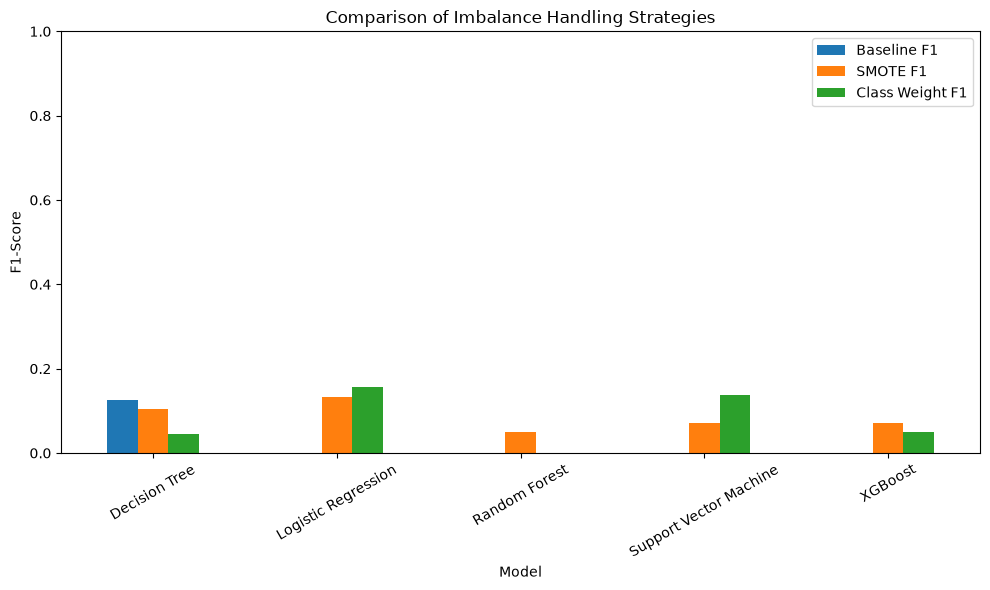

In [47]:
plot_df = strategy_comparison.set_index("Model")[
    ["Baseline F1", "SMOTE F1", "Class Weight F1"]
]

plot_df.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of Imbalance Handling Strategies")
plt.ylabel("F1-Score")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Feature Relevance Analysis

Mutual Information is used to measure how much information each feature provides about the target class.

In [48]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=RANDOM_STATE
)

mi_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Mutual Information": mi_scores
})

mi_df = mi_df.sort_values(
    "Mutual Information",
    ascending=False
).reset_index(drop=True)

mi_df.round(4)

,Feature,Mutual Information
0,protocol_type_TCP,0.0088
1,protocol_type_UDP,0.0072
2,packet_size,0.0065
3,packet_count_5s,0.0039
4,src_ip_192.168.1.2,0.0032
5,src_ip_192.168.1.3,0.0018
6,tcp_flags_SYN-ACK,0.0012
7,inter_arrival_time,0.0000
8,frequency_band_energy,0.0000
9,spectral_entropy,0.0000


## Mutual Information Scores

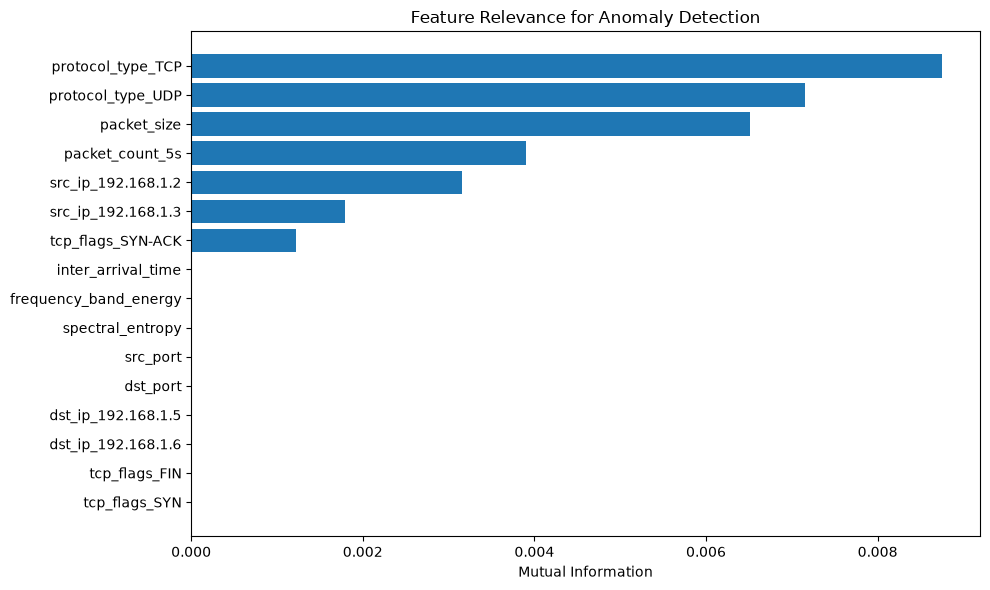

In [49]:
plt.figure(figsize=(10, 6))

plt.barh(
    mi_df["Feature"],
    mi_df["Mutual Information"]
)

plt.gca().invert_yaxis()

plt.xlabel("Mutual Information")
plt.title("Feature Relevance for Anomaly Detection")

plt.tight_layout()
plt.show()

### Observation

Mutual Information shows that only a small number of features have relatively strong dependence on the target. Several features have scores close to zero, suggesting limited individual predictive information. Feature selection will therefore be evaluated using cross-validation instead of removing features manually.

## Evaluate Different Feature Subsets

Different numbers of top-ranked features are evaluated using cross-validation. Feature selection is performed inside the pipeline to avoid data leakage.

In [50]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif

In [51]:
def mi_score(X, y):
    return mutual_info_classif(
        X,
        y,
        random_state=RANDOM_STATE
    )

In [52]:
feature_counts = [4, 6, 8, 12, X_train.shape[1]]

feature_selection_results = []

for k in feature_counts:

    model = Pipeline([
        (
            "feature_selection",
            SelectKBest(
                score_func=mi_score,
                k=k
            )
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=2000,
                random_state=RANDOM_STATE
            )
        )
    ])

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    feature_selection_results.append({
        "Number of Features": k,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean()
    })

feature_selection_df = pd.DataFrame(
    feature_selection_results
)

feature_selection_df.round(4)

,Number of Features,Accuracy,Precision,Recall,F1-Score
0,4,0.5225,0.1005,0.4625,0.1649
1,6,0.5438,0.0940,0.4125,0.1531
2,8,0.5337,0.0853,0.3750,0.1389
3,12,0.5525,0.0889,0.3750,0.1436
4,16,0.5688,0.0965,0.4000,0.1555


## Feature Selection Performance

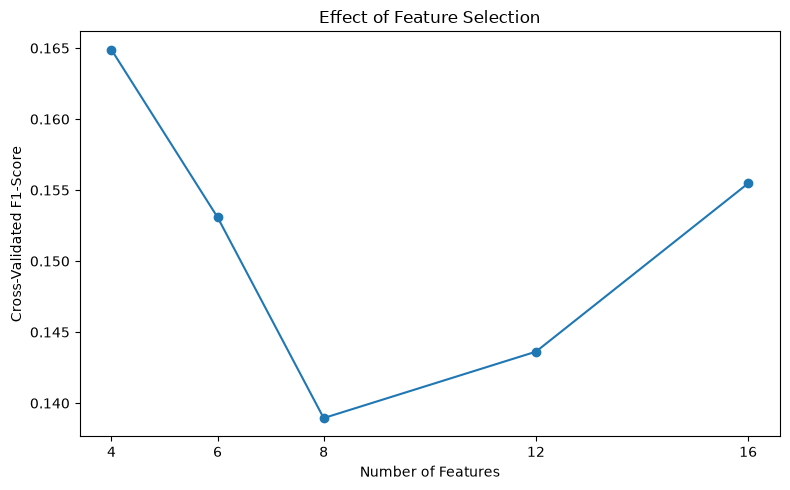

In [53]:
plt.figure(figsize=(8, 5))

plt.plot(
    feature_selection_df["Number of Features"],
    feature_selection_df["F1-Score"],
    marker="o"
)

plt.xlabel("Number of Features")
plt.ylabel("Cross-Validated F1-Score")
plt.title("Effect of Feature Selection")

plt.xticks(feature_counts)
plt.tight_layout()
plt.show()

### Observation

The best cross-validated F1-score is obtained using the top 4 Mutual Information features. Adding more features does not improve performance consistently, suggesting that several variables add little useful information or noise.

## Selected Features

In [54]:
selected_features = mi_df.head(4)["Feature"].tolist()

print("Selected features:")

for feature in selected_features:
    print(feature)

Selected features:
protocol_type_TCP
protocol_type_UDP
packet_size
packet_count_5s


## Supervised Models with Selected Features

The five supervised models are evaluated again using only the four highest-ranked features.

In [55]:
X_train_selected = X_train[selected_features]

selected_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            class_weight="balanced",
            probability=True,
            random_state=RANDOM_STATE
        ))
    ]),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.9,
        colsample_bytree=0.9,
        scale_pos_weight=9,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

## Selected Feature Cross-Validation

In [56]:
selected_cv_results = []

for name, model in selected_models.items():

    scores = cross_validate(
        model,
        X_train_selected,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    selected_cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean()
    })

selected_cv_df = pd.DataFrame(
    selected_cv_results
).sort_values(
    "F1-Score",
    ascending=False
).reset_index(drop=True)

selected_cv_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Support Vector Machine,0.5650,0.1324,0.5875,0.2157
1,XGBoost,0.7787,0.1602,0.2875,0.2054
2,Logistic Regression,0.5450,0.1114,0.5125,0.1829
3,Random Forest,0.8238,0.1396,0.1375,0.1382
4,Decision Tree,0.8200,0.1022,0.1000,0.1000


### Observation

Using the top 4 selected features improves the cross-validated F1-score. Support Vector Machine performs best with an F1-score of 0.2157, followed by XGBoost with 0.2054. This suggests that removing weak features reduces noise and improves anomaly detection performance.

## Hyperparameter Tuning

The two best-performing models, Support Vector Machine and XGBoost, are tuned using cross-validation on the selected features.

In [57]:
from sklearn.model_selection import GridSearchCV

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        class_weight="balanced",
        probability=True,
        random_state=RANDOM_STATE
    ))
])

svm_param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", "auto", 0.01, 0.1, 1],
    "model__kernel": ["rbf"]
}

svm_grid = GridSearchCV(
    svm_pipeline,
    svm_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

svm_grid.fit(
    X_train_selected,
    y_train
)

print("Best Parameters:")
print(svm_grid.best_params_)

print("\nBest CV F1-Score:")
print(round(svm_grid.best_score_, 4))

Best Parameters:
{'model__C': 0.1, 'model__gamma': 1, 'model__kernel': 'rbf'}

Best CV F1-Score:
0.2273


## XGBoost Hyperparameter Tuning

In [58]:
xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=9,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [2, 3, 4, 5],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    xgb_model,
    xgb_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

xgb_grid.fit(
    X_train_selected,
    y_train
)

print("Best Parameters:")
print(xgb_grid.best_params_)

print("\nBest CV F1-Score:")
print(round(xgb_grid.best_score_, 4))

Best Parameters:
{'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}

Best CV F1-Score:
0.199


## Compare Tuned Models

In [59]:
tuned_model_comparison = pd.DataFrame({
    "Model": [
        "Support Vector Machine",
        "XGBoost"
    ],
    "Best CV F1-Score": [
        svm_grid.best_score_,
        xgb_grid.best_score_
    ]
})

tuned_model_comparison = (
    tuned_model_comparison
    .sort_values(
        "Best CV F1-Score",
        ascending=False
    )
    .reset_index(drop=True)
)

tuned_model_comparison.round(4)

,Model,Best CV F1-Score
0,Support Vector Machine,0.2273
1,XGBoost,0.1990


## Select Final Supervised Model

In [60]:
if svm_grid.best_score_ >= xgb_grid.best_score_:
    final_supervised_name = "Support Vector Machine"
    final_supervised_model = svm_grid.best_estimator_
else:
    final_supervised_name = "XGBoost"
    final_supervised_model = xgb_grid.best_estimator_

print("Selected final model:", final_supervised_name)

Selected final model: Support Vector Machine


## Final Supervised Test Evaluation

The selected model is evaluated once on the untouched test set.

In [62]:
X_test_selected = X_test[selected_features]

y_pred_final = final_supervised_model.predict(
    X_test_selected
)

final_accuracy = accuracy_score(
    y_test,
    y_pred_final
)

final_precision = precision_score(
    y_test,
    y_pred_final,
    zero_division=0
)

final_recall = recall_score(
    y_test,
    y_pred_final,
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    y_pred_final,
    zero_division=0
)

print("Model:", final_supervised_name)
print("Accuracy:", round(final_accuracy, 4))
print("Precision:", round(final_precision, 4))
print("Recall:", round(final_recall, 4))
print("F1-Score:", round(final_f1, 4))

Model: Support Vector Machine
Accuracy: 0.585
Precision: 0.1379
Recall: 0.6
F1-Score: 0.2243


## Classification Report

In [63]:
print(
    classification_report(
        y_test,
        y_pred_final,
        target_names=[
            "Normal",
            "Anomaly"
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

      Normal     0.9292    0.5833    0.7167       180
     Anomaly     0.1379    0.6000    0.2243        20

    accuracy                         0.5850       200
   macro avg     0.5336    0.5917    0.4705       200
weighted avg     0.8501    0.5850    0.6675       200



## Confusion Matrix

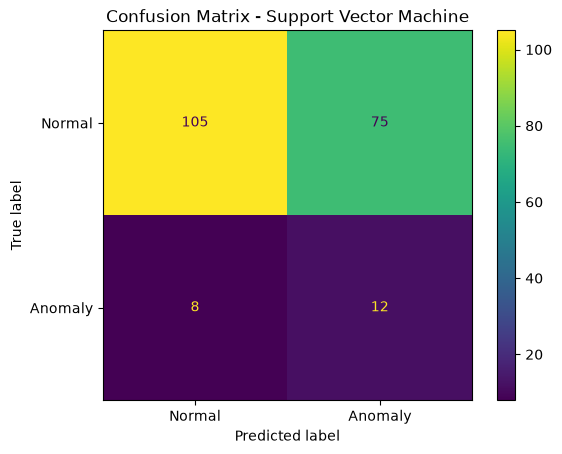

In [64]:
cm = confusion_matrix(
    y_test,
    y_pred_final
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Normal",
        "Anomaly"
    ]
)

disp.plot()

plt.title(
    f"Confusion Matrix - {final_supervised_name}"
)

plt.show()

### Observation

The tuned Support Vector Machine achieved the best supervised test performance with an F1-score of 0.2243 and Recall of 0.6000. The relatively high Recall shows that the model detects a larger proportion of anomalous traffic, but the low Precision indicates a high number of false positives.

The result shows that the dataset is difficult to separate cleanly. Improving anomaly Recall reduces overall Accuracy and Precision, highlighting the trade-off between detecting more attacks and generating false alarms.

### Observation

Only normal training samples are used to learn normal network behaviour for the unsupervised anomaly detection models.

## Prepare Normal Training Data

In [67]:
X_normal_train = X_train[y_train == 0].copy()

print("Normal training samples:", X_normal_train.shape[0])
print("Number of features:", X_normal_train.shape[1])

Normal training samples: 720
Number of features: 16


### Observation

Only normal training samples are used to learn normal network behaviour for the unsupervised anomaly detection models.

## Scale Data for Unsupervised Models

In [68]:
unsup_scaler = StandardScaler()

X_normal_train_scaled = unsup_scaler.fit_transform(
    X_normal_train
)

X_test_scaled = unsup_scaler.transform(
    X_test
)

print("Scaled training shape:", X_normal_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

Scaled training shape: (720, 16)
Scaled test shape: (200, 16)


## Evaluation Function

In [69]:
def evaluate_anomaly_model(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_true,
            y_pred,
            zero_division=0
        )
    }

## Isolation Forest

In [70]:
isolation_forest = IsolationForest(
    n_estimators=300,
    contamination=0.10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

isolation_forest.fit(
    X_normal_train_scaled
)

if_pred_raw = isolation_forest.predict(
    X_test_scaled
)

if_pred = np.where(
    if_pred_raw == -1,
    1,
    0
)

if_result = evaluate_anomaly_model(
    "Isolation Forest",
    y_test,
    if_pred
)

if_result

{'Model': 'Isolation Forest',
 'Accuracy': 0.77,
 'Precision': 0.09375,
 'Recall': 0.15,
 'F1-Score': 0.11538461538461539}

### Observation

Isolation Forest detects anomalies by isolating unusual observations using random feature splits. Its performance is evaluated using Precision, Recall and F1-score rather than Accuracy alone.

Isolation Forest achieved an F1-score of 0.1154 with Recall of 0.15. The model detects only a small portion of anomalous traffic, so its anomaly detection performance is limited on this dataset.

## Gaussian Mixture Model

In [71]:
gmm = GaussianMixture(
    n_components=3,
    covariance_type="full",
    reg_covar=1e-6,
    random_state=RANDOM_STATE
)

gmm.fit(
    X_normal_train_scaled
)

gmm_train_scores = -gmm.score_samples(
    X_normal_train_scaled
)

gmm_test_scores = -gmm.score_samples(
    X_test_scaled
)

gmm_threshold = np.quantile(
    gmm_train_scores,
    0.90
)

gmm_pred = (
    gmm_test_scores > gmm_threshold
).astype(int)

gmm_result = evaluate_anomaly_model(
    "Gaussian Mixture Model",
    y_test,
    gmm_pred
)

gmm_result

{'Model': 'Gaussian Mixture Model',
 'Accuracy': 0.76,
 'Precision': 0.08823529411764706,
 'Recall': 0.15,
 'F1-Score': 0.1111111111111111}

### Observation

The Gaussian Mixture Model achieved an F1-score of 0.1111 with Recall of 0.15. Its performance is similar to Isolation Forest, indicating that the normal and anomalous samples are not well separated by a simple density-based model.

## Hidden Markov Model

In [72]:
hmm = GaussianHMM(
    n_components=3,
    covariance_type="diag",
    n_iter=200,
    random_state=RANDOM_STATE
)

hmm.fit(
    X_normal_train_scaled
)

,n_components,3
,random_state,42
,n_iter,200
,covariance_type,'diag'
,min_covar,0.001
,startprob_prior,1.0
,transmat_prior,1.0
,means_prior,0
,means_weight,0
,covars_prior,0.01
,covars_weight,1


In [73]:
def hmm_anomaly_scores(model, data):
    scores = []

    for row in data:
        score = model.score(
            row.reshape(1, -1)
        )

        scores.append(
            -score
        )

    return np.array(scores)

In [74]:
hmm_train_scores = hmm_anomaly_scores(
    hmm,
    X_normal_train_scaled
)

hmm_test_scores = hmm_anomaly_scores(
    hmm,
    X_test_scaled
)

hmm_threshold = np.quantile(
    hmm_train_scores,
    0.90
)

hmm_pred = (
    hmm_test_scores > hmm_threshold
).astype(int)

hmm_result = evaluate_anomaly_model(
    "Hidden Markov Model",
    y_test,
    hmm_pred
)

hmm_result

{'Model': 'Hidden Markov Model',
 'Accuracy': 0.835,
 'Precision': 0.11764705882352941,
 'Recall': 0.1,
 'F1-Score': 0.10810810810810811}

### Observation

The Hidden Markov Model achieved an F1-score of 0.1081 with Recall of 0.10. Although its Accuracy is relatively high, it detects only a small fraction of anomalies, so its practical anomaly detection performance is weak.

## Elliptic Envelope

In [75]:
elliptic = EllipticEnvelope(
    contamination=0.10,
    random_state=RANDOM_STATE
)

elliptic.fit(
    X_normal_train_scaled
)

elliptic_pred_raw = elliptic.predict(
    X_test_scaled
)

elliptic_pred = np.where(
    elliptic_pred_raw == -1,
    1,
    0
)

elliptic_result = evaluate_anomaly_model(
    "Elliptic Envelope",
    y_test,
    elliptic_pred
)

elliptic_result

{'Model': 'Elliptic Envelope',
 'Accuracy': 0.75,
 'Precision': 0.08333333333333333,
 'Recall': 0.15,
 'F1-Score': 0.10714285714285714}

### Observation

Elliptic Envelope achieved an F1-score of 0.1071 with Recall of 0.15. The model detects only a small portion of anomalies and performs similarly to the other statistical anomaly detection methods.

## Autoencoder

In [76]:
input_dim = X_normal_train_scaled.shape[1]

autoencoder = keras.Sequential([
    layers.Input(shape=(input_dim,)),

    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(4, activation="relu"),

    layers.Dense(8, activation="relu"),
    layers.Dense(16, activation="relu"),

    layers.Dense(input_dim, activation="linear")
])

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           272 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 900 (3.52 KB)

 Trainable params: 900 (3.52 KB)

 Non-trainable params: 0 (0.00 B)

## Train Autoencoder

In [77]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = autoencoder.fit(
    X_normal_train_scaled,
    X_normal_train_scaled,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.0272 - val_loss: 1.0216
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9949 - val_loss: 0.9984
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9776 - val_loss: 0.9840
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9635 - val_loss: 0.9711
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9499 - val_loss: 0.9573
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9352 - val_loss: 0.9423
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9192 - val_loss: 0.9262
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9025 - val_loss: 0.9099
Epoch 9/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8853 - val_loss: 0.8929
Epoch 10/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8684 - val_loss: 0.8761
Epoch 11/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8525 - val_loss: 0.8610
Epoch 12/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.

## Reconstruction Error and Threshold

In [78]:
train_reconstruction = autoencoder.predict(
    X_normal_train_scaled,
    verbose=0
)

train_error = np.mean(
    np.square(
        X_normal_train_scaled - train_reconstruction
    ),
    axis=1
)

ae_threshold = np.quantile(
    train_error,
    0.90
)

print("Autoencoder threshold:", ae_threshold)

Autoencoder threshold: 0.770795972593095


In [79]:
test_reconstruction = autoencoder.predict(
    X_test_scaled,
    verbose=0
)

test_error = np.mean(
    np.square(
        X_test_scaled - test_reconstruction
    ),
    axis=1
)

ae_pred = (
    test_error > ae_threshold
).astype(int)

ae_result = evaluate_anomaly_model(
    "Autoencoder",
    y_test,
    ae_pred
)

ae_result

{'Model': 'Autoencoder',
 'Accuracy': 0.755,
 'Precision': 0.10810810810810811,
 'Recall': 0.2,
 'F1-Score': 0.14035087719298245}

### Observation

The Autoencoder achieved the best unsupervised performance with an F1-score of 0.1404 and Recall of 0.20. Although its performance is still limited, it detects a larger proportion of anomalies than the other unsupervised methods.

## Compare Unsupervised Models

In [80]:
unsupervised_results = [
    if_result,
    gmm_result,
    hmm_result,
    elliptic_result,
    ae_result
]

unsupervised_results_df = pd.DataFrame(
    unsupervised_results
)

unsupervised_results_df = (
    unsupervised_results_df
    .sort_values(
        "F1-Score",
        ascending=False
    )
    .reset_index(drop=True)
)

unsupervised_results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Autoencoder,0.755,0.1081,0.20,0.1404
1,Isolation Forest,0.770,0.0938,0.15,0.1154
2,Gaussian Mixture Model,0.760,0.0882,0.15,0.1111
3,Hidden Markov Model,0.835,0.1176,0.10,0.1081
4,Elliptic Envelope,0.750,0.0833,0.15,0.1071


## Unsupervised Model Performance

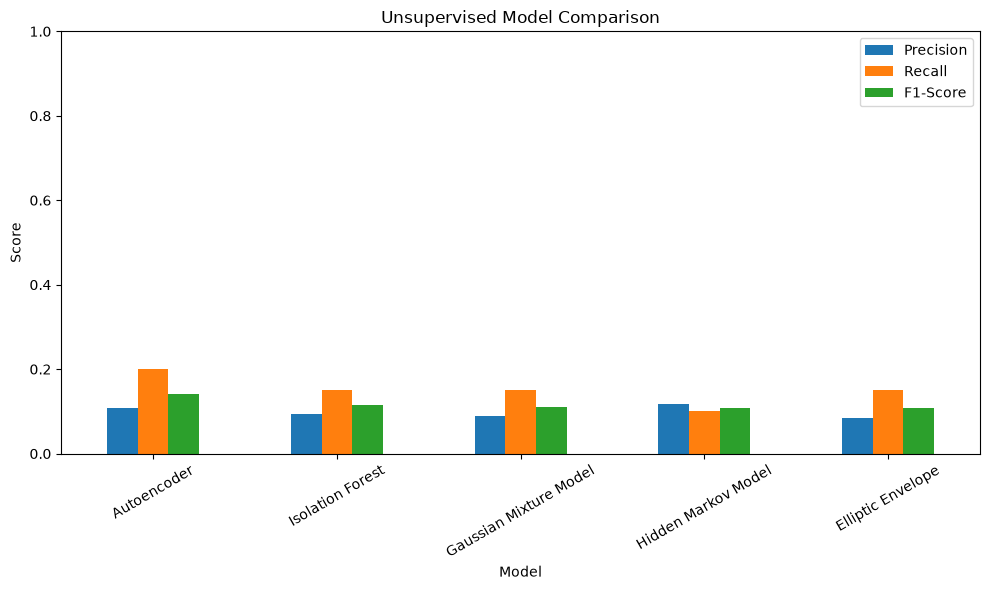

In [81]:
plot_df = (
    unsupervised_results_df
    .set_index("Model")
)

plot_df[
    [
        "Precision",
        "Recall",
        "F1-Score"
    ]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Unsupervised Model Comparison"
)

plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### Observation

The Autoencoder performs best among the unsupervised models, while Isolation Forest, Gaussian Mixture Model, Hidden Markov Model and Elliptic Envelope achieve lower F1-scores. Overall, the unsupervised models struggle to separate anomalous traffic from normal traffic on this small dataset.

# Final Comparison

In [82]:
final_comparison = pd.DataFrame([
    {
        "Model": final_supervised_name,
        "Type": "Supervised",
        "Accuracy": final_accuracy,
        "Precision": final_precision,
        "Recall": final_recall,
        "F1-Score": final_f1
    },
    {
        "Model": unsupervised_results_df.iloc[0]["Model"],
        "Type": "Unsupervised",
        "Accuracy": unsupervised_results_df.iloc[0]["Accuracy"],
        "Precision": unsupervised_results_df.iloc[0]["Precision"],
        "Recall": unsupervised_results_df.iloc[0]["Recall"],
        "F1-Score": unsupervised_results_df.iloc[0]["F1-Score"]
    }
])

final_comparison.round(4)

,Model,Type,Accuracy,Precision,Recall,F1-Score
0,Support Vector Machine,Supervised,0.585,0.1379,0.6,0.2243
1,Autoencoder,Unsupervised,0.755,0.1081,0.2,0.1404


## Final Performance Comparison

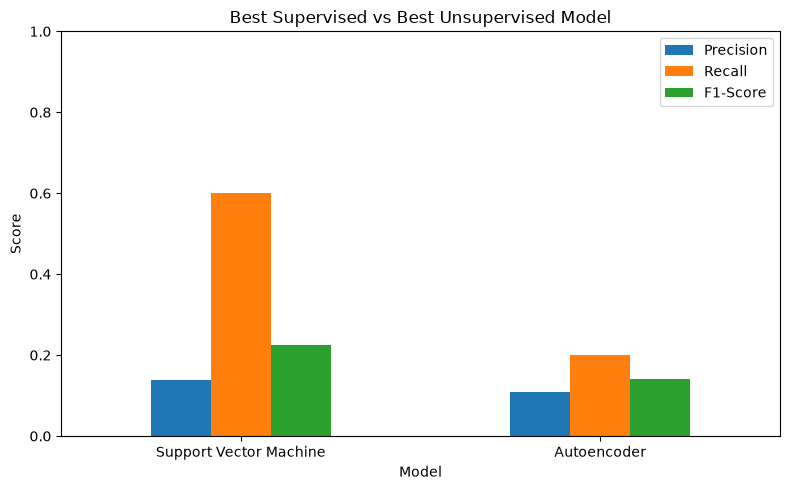

In [83]:
comparison_plot = final_comparison.set_index("Model")[
    ["Precision", "Recall", "F1-Score"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Best Supervised vs Best Unsupervised Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Observation

The tuned Support Vector Machine performs better than the unsupervised models in terms of Recall and F1-score. The Autoencoder is the strongest unsupervised model, but both approaches show that the small dataset has limited separation between normal and anomalous traffic.

## Save Results

In [84]:
RESULTS_PATH = Path("../results")

RESULTS_PATH.mkdir(
    parents=True,
    exist_ok=True
)

baseline_cv_df.round(4).to_csv(
    RESULTS_PATH / "baseline_cv_results.csv",
    index=False
)

smote_cv_df.round(4).to_csv(
    RESULTS_PATH / "smote_cv_results.csv",
    index=False
)

weighted_cv_df.round(4).to_csv(
    RESULTS_PATH / "weighted_cv_results.csv",
    index=False
)

selected_cv_df.round(4).to_csv(
    RESULTS_PATH / "selected_feature_results.csv",
    index=False
)

unsupervised_results_df.round(4).to_csv(
    RESULTS_PATH / "unsupervised_results.csv",
    index=False
)

final_comparison.round(4).to_csv(
    RESULTS_PATH / "final_small_dataset_results.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


# Conclusion

The small dataset was evaluated using both supervised classification and unsupervised anomaly detection methods.

The original class imbalance caused several baseline models to achieve high Accuracy while failing to detect anomalies. SMOTE and class weighting improved anomaly Recall, but overall performance remained limited.

Mutual Information feature selection improved the supervised models, and the tuned Support Vector Machine achieved the best final supervised performance with an F1-score of 0.2243 and Recall of 0.60.

Among the unsupervised methods, the Autoencoder performed best with an F1-score of 0.1404 and Recall of 0.20.

Overall, the results indicate that the small dataset contains limited predictive separation between normal and anomalous traffic. The next stage therefore moves to larger and more realistic network intrusion datasets.